# Advanced ML models: LightGBM, CatBoost and Extra Trees

Three more models that suit this kind of data (numeric features, hundreds of thousands of rows):

| Model | How it differs from what you have | Why it fits |
|---|---|---|
| **LightGBM** | Gradient-boosted trees like XGBoost, but grows trees leaf-wise and uses histogram binning | Often matches or beats XGBoost and trains faster |
| **CatBoost** | Boosting with "ordered" training that reduces overfitting | Strong with little tuning, and different enough from XGBoost to add diversity to an ensemble |
| **Extra Trees** | Like Random Forest, but picks split points at random | Very fast, adds variety to the ensemble, and is less prone to overfitting noise |

All three are trained for binary and multiclass, with class weights from `meta.json`, and evaluated with the same metrics as before (now including accuracy). They are saved so the ensemble notebook can use them.

Install once if needed: `pip install lightgbm catboost`. Run after the preprocessing notebook.

## 1. Imports

In [1]:
# %pip install lightgbm catboost matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.ensemble import ExtraTreesClassifier

## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LGBM_PARAMS = dict(n_estimators=1000, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.8, reg_lambda=1.0, min_child_samples=20,
                   n_jobs=-1, random_state=SEED, verbose=-1)
CATBOOST_ITERATIONS = 600       # CatBoost multiclass is the slowest model here; lower this if it drags
CATBOOST_DEPTH = 8
ET_PARAMS = dict(n_estimators=300, min_samples_leaf=2, max_features="sqrt",
                 class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
EARLY_STOPPING = 30

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'Reconnaissance', 'Fuzzers', 'Generic', 'Exploit-like']


## 4. Helpers (same evaluation as every other notebook, now with accuracy)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

In [5]:
w_bin = np.array([cw_bin[0], cw_bin[1]])[yb_train]                       # per-row weights for LightGBM
w_multi = np.array([cw_multi[i] for i in range(n_classes)])[ym_train]
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

## 5. LightGBM

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


binary: 905 trees in 6.2s
              precision    recall  f1-score   support

      Normal     0.9084    0.9647    0.9357     11200
      Attack     0.9830    0.9543    0.9684     23869

    accuracy                         0.9577     35069
   macro avg     0.9457    0.9595    0.9521     35069
weighted avg     0.9591    0.9577    0.9580     35069

ROC-AUC:              0.9952
False positive rate:  0.0353  (395 normal flows flagged as attacks)
False negative rate:  0.0457  (1090 attacks missed)


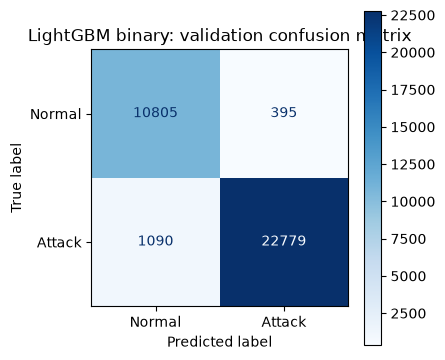

In [6]:
t0 = time.time()
lgbm_bin = lgb.LGBMClassifier(objective="binary", **LGBM_PARAMS).fit(
    X_train, yb_train, sample_weight=w_bin, eval_set=[(X_val, yb_val)],
    callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)])
print(f"binary: {lgbm_bin.best_iteration_} trees in {time.time() - t0:.1f}s")
proba = lgbm_bin.predict_proba(X_val)[:, 1]
row_lgbm_bin = report_binary(yb_val, (proba >= 0.5).astype(int), "LightGBM binary", score=proba,
                             ms=ms_per_1000(lgbm_bin.predict, X_val))

c:\Users\Adhya Razdan\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


multiclass: 133 trees in 5.5s
                precision    recall  f1-score   support

        Normal     0.9790    0.8849    0.9296     11200
Reconnaissance     0.7595    0.8109    0.7843      2099
       Fuzzers     0.7008    0.8666    0.7749      3637
       Generic     0.9977    0.9834    0.9905      8000
  Exploit-like     0.9034    0.9202    0.9117     10133

      accuracy                         0.9112     35069
     macro avg     0.8681    0.8932    0.8782     35069
  weighted avg     0.9194    0.9112    0.9136     35069

macro F1:    0.8782
weighted F1: 0.9136


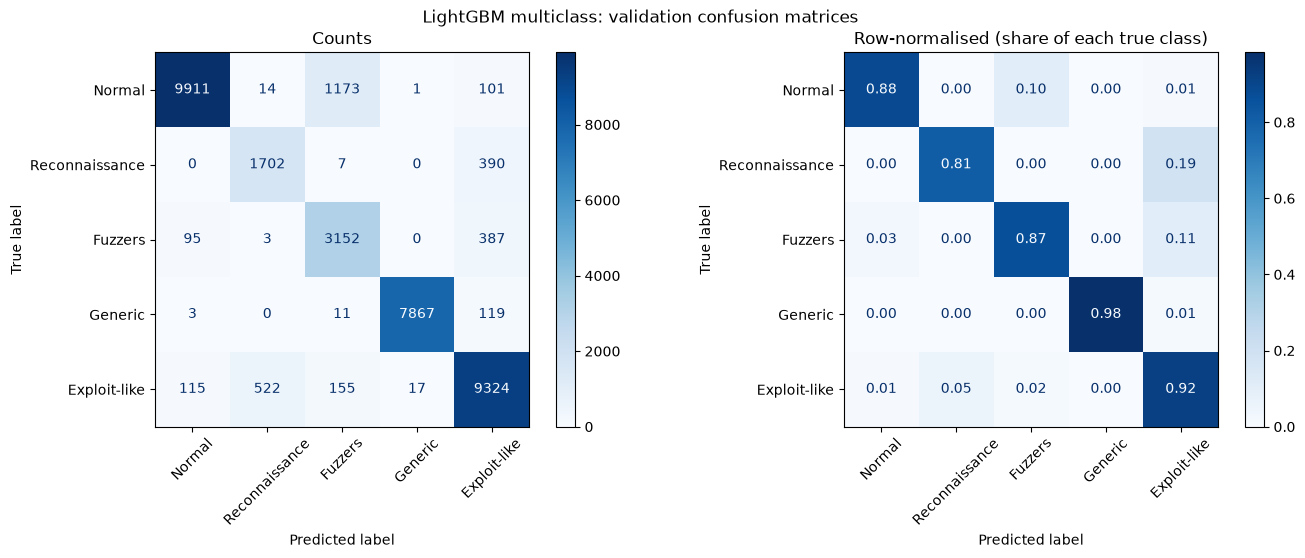

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,11.51,88.49
1,Reconnaissance,2099,100.00,81.09
2,Fuzzers,3637,97.39,86.66
3,Generic,8000,99.96,98.34
4,Exploit-like,10133,98.87,92.02


In [7]:
t0 = time.time()
lgbm_multi = lgb.LGBMClassifier(objective="multiclass", **LGBM_PARAMS).fit(
    X_train, ym_train, sample_weight=w_multi, eval_set=[(X_val, ym_val)],
    callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)])
print(f"multiclass: {lgbm_multi.best_iteration_} trees in {time.time() - t0:.1f}s")
row_lgbm_multi = report_multiclass(ym_val, lgbm_multi.predict(X_val), "LightGBM multiclass",
                                   ms=ms_per_1000(lgbm_multi.predict, X_val))

joblib.dump(lgbm_bin, mdir / "lgbm_binary.joblib", compress=3)
joblib.dump(lgbm_multi, mdir / "lgbm_multiclass.joblib", compress=3)
pd.DataFrame([row_lgbm_bin, row_lgbm_multi]).to_csv(mdir / "lgbm_validation_summary.csv", index=False)

## 6. CatBoost

binary: 598 trees in 14.1s
              precision    recall  f1-score   support

      Normal     0.8984    0.9683    0.9321     11200
      Attack     0.9846    0.9486    0.9663     23869

    accuracy                         0.9549     35069
   macro avg     0.9415    0.9585    0.9492     35069
weighted avg     0.9571    0.9549    0.9553     35069

ROC-AUC:              0.9950
False positive rate:  0.0317  (355 normal flows flagged as attacks)
False negative rate:  0.0514  (1226 attacks missed)


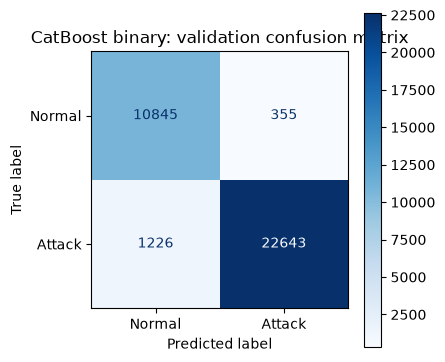

In [8]:
t0 = time.time()
cb_bin = CatBoostClassifier(
    iterations=CATBOOST_ITERATIONS, depth=CATBOOST_DEPTH, learning_rate=0.1,
    loss_function="Logloss", class_weights=[cw_bin[0], cw_bin[1]],
    early_stopping_rounds=EARLY_STOPPING, random_seed=SEED, verbose=0, thread_count=-1)
cb_bin.fit(X_train, yb_train, eval_set=(X_val, yb_val))
print(f"binary: {cb_bin.get_best_iteration() + 1} trees in {time.time() - t0:.1f}s")
proba = cb_bin.predict_proba(X_val)[:, 1]
row_cb_bin = report_binary(yb_val, (proba >= 0.5).astype(int), "CatBoost binary", score=proba,
                           ms=ms_per_1000(cb_bin.predict, X_val))

multiclass: 217 trees in 23.4s
                precision    recall  f1-score   support

        Normal     0.9838    0.8670    0.9217     11200
Reconnaissance     0.7979    0.8128    0.8053      2099
       Fuzzers     0.6643    0.8809    0.7574      3637
       Generic     0.9995    0.9808    0.9900      8000
  Exploit-like     0.9011    0.9238    0.9123     10133

      accuracy                         0.9076     35069
     macro avg     0.8693    0.8930    0.8774     35069
  weighted avg     0.9192    0.9076    0.9106     35069

macro F1:    0.8774
weighted F1: 0.9106


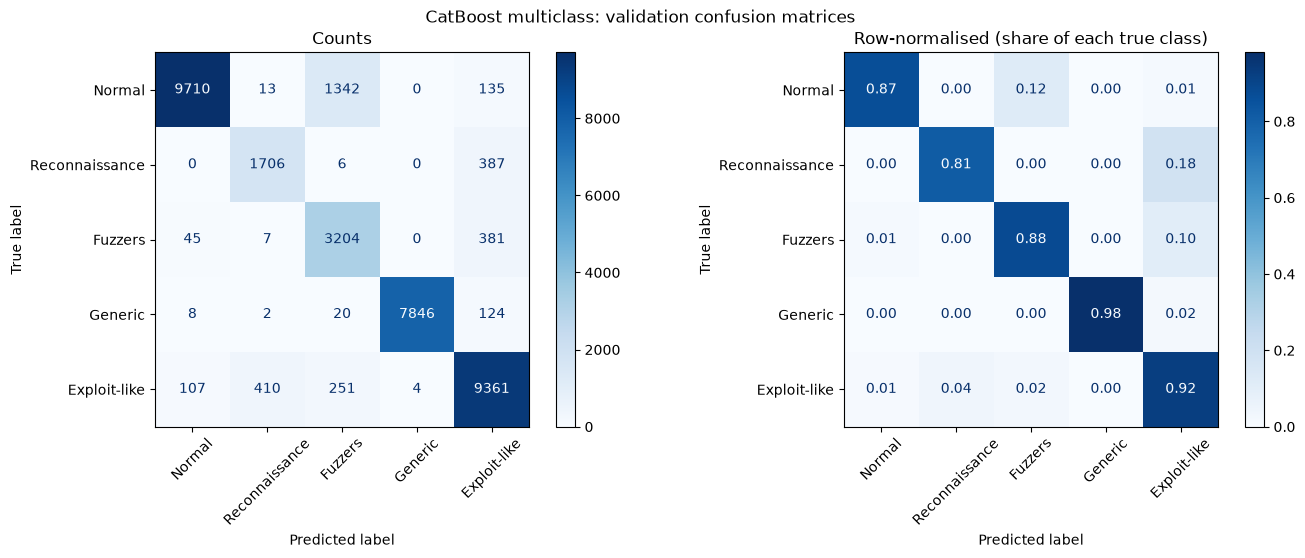

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,13.30,86.70
1,Reconnaissance,2099,100.00,81.28
2,Fuzzers,3637,98.76,88.09
3,Generic,8000,99.90,98.08
4,Exploit-like,10133,98.94,92.38


In [9]:
t0 = time.time()
cb_multi = CatBoostClassifier(
    iterations=CATBOOST_ITERATIONS, depth=CATBOOST_DEPTH, learning_rate=0.1,
    loss_function="MultiClass", class_weights=[cw_multi[i] for i in range(n_classes)],
    early_stopping_rounds=EARLY_STOPPING, random_seed=SEED, verbose=0, thread_count=-1)
cb_multi.fit(X_train, ym_train, eval_set=(X_val, ym_val))
print(f"multiclass: {cb_multi.get_best_iteration() + 1} trees in {time.time() - t0:.1f}s")
pred = cb_multi.predict(X_val).ravel().astype(int)
row_cb_multi = report_multiclass(ym_val, pred, "CatBoost multiclass",
                                 ms=ms_per_1000(lambda X: cb_multi.predict(X), X_val))

cb_bin.save_model(str(mdir / "catboost_binary.cbm"))
cb_multi.save_model(str(mdir / "catboost_multiclass.cbm"))
pd.DataFrame([row_cb_bin, row_cb_multi]).to_csv(mdir / "catboost_validation_summary.csv", index=False)

## 7. Extra Trees

binary trained in 12.6s
              precision    recall  f1-score   support

      Normal     0.9044    0.9609    0.9318     11200
      Attack     0.9811    0.9524    0.9665     23869

    accuracy                         0.9551     35069
   macro avg     0.9428    0.9566    0.9492     35069
weighted avg     0.9566    0.9551    0.9554     35069

ROC-AUC:              0.9945
False positive rate:  0.0391  (438 normal flows flagged as attacks)
False negative rate:  0.0476  (1137 attacks missed)


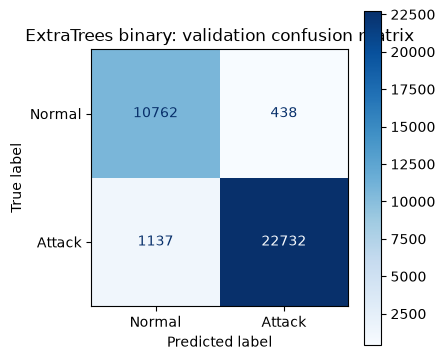

In [10]:
t0 = time.time()
et_bin = ExtraTreesClassifier(**ET_PARAMS).fit(X_train, yb_train)
print(f"binary trained in {time.time() - t0:.1f}s")
proba = et_bin.predict_proba(X_val)[:, 1]
row_et_bin = report_binary(yb_val, (proba >= 0.5).astype(int), "ExtraTrees binary", score=proba,
                           ms=ms_per_1000(et_bin.predict, X_val))

multiclass trained in 11.8s
                precision    recall  f1-score   support

        Normal     0.9793    0.8799    0.9270     11200
Reconnaissance     0.5482    0.8128    0.6548      2099
       Fuzzers     0.6710    0.8568    0.7526      3637
       Generic     0.9940    0.9804    0.9872      8000
  Exploit-like     0.8968    0.8284    0.8612     10133

      accuracy                         0.8815     35069
     macro avg     0.8179    0.8716    0.8365     35069
  weighted avg     0.9011    0.8815    0.8873     35069

macro F1:    0.8365
weighted F1: 0.8873


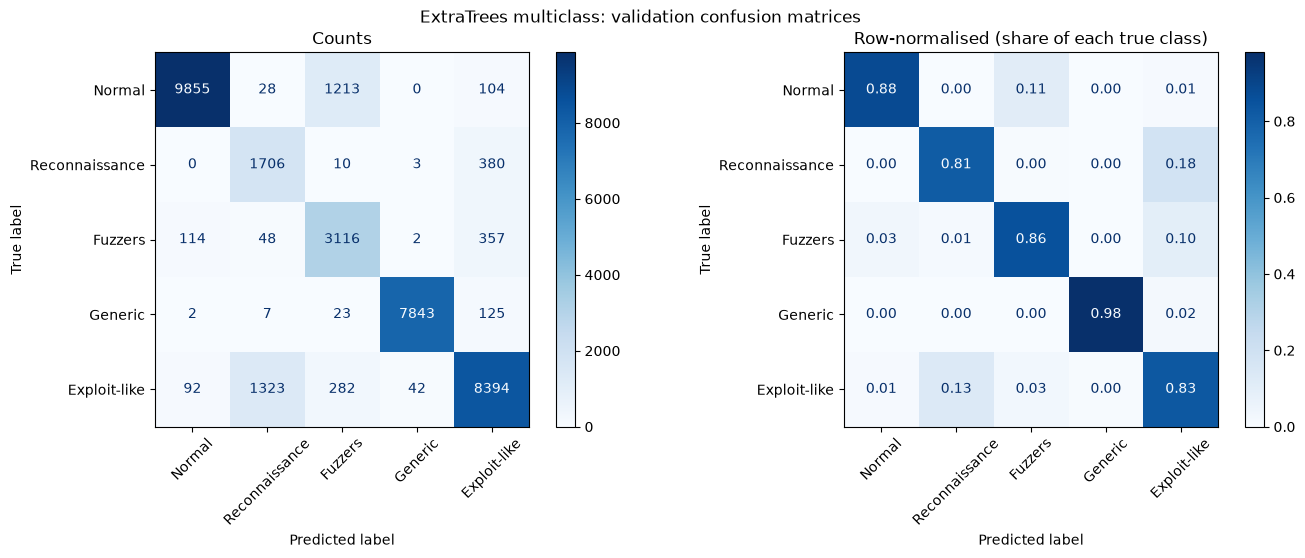

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,12.01,87.99
1,Reconnaissance,2099,100.00,81.28
2,Fuzzers,3637,96.87,85.68
3,Generic,8000,99.98,98.04
4,Exploit-like,10133,99.09,82.84


lgbm_binary.joblib                     2.81 MB
lgbm_iw_binary.joblib                  1.35 MB
lgbm_iw_multiclass.joblib              2.32 MB
lgbm_multiclass.joblib                 2.08 MB
lgbm_validation_summary.csv            0.00 MB
catboost_binary.cbm                    2.54 MB
catboost_multiclass.cbm                2.69 MB
catboost_validation_summary.csv        0.00 MB
extratrees_binary.joblib              60.82 MB
extratrees_multiclass.joblib         111.80 MB
extratrees_validation_summary.csv      0.00 MB


In [11]:
t0 = time.time()
et_multi = ExtraTreesClassifier(**ET_PARAMS).fit(X_train, ym_train)
print(f"multiclass trained in {time.time() - t0:.1f}s")
row_et_multi = report_multiclass(ym_val, et_multi.predict(X_val), "ExtraTrees multiclass",
                                 ms=ms_per_1000(et_multi.predict, X_val))

joblib.dump(et_bin, mdir / "extratrees_binary.joblib", compress=3)
joblib.dump(et_multi, mdir / "extratrees_multiclass.joblib", compress=3)
pd.DataFrame([row_et_bin, row_et_multi]).to_csv(mdir / "extratrees_validation_summary.csv", index=False)
for f in sorted(mdir.glob("lgbm_*")) + sorted(mdir.glob("catboost_*")) + sorted(mdir.glob("extratrees_*")):
    print(f"{f.name:34s} {f.stat().st_size / 1e6:8.2f} MB")

## 8. Compare with every model run so far

In [12]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows,accuracy
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,25.2,NaN
2,ANN multiclass (macro),0.8484,0.8817,0.8595,NaN,20.4,NaN
3,CatBoost binary,0.9846,0.9486,0.9663,0.0317,1.1,0.9549
4,CatBoost multiclass (macro),0.8693,0.8930,0.8774,NaN,1.1,0.9076
5,CNN binary,0.9757,0.9403,0.9577,0.0499,19.4,NaN
6,CNN multiclass (macro),0.8679,0.8914,0.8751,NaN,19.2,NaN
7,DNN binary,0.9791,0.9345,0.9563,0.0424,18.8,NaN
8,DNN multiclass (macro),0.8660,0.8908,0.8733,NaN,19.4,NaN
9,ExtraTrees binary,0.9811,0.9524,0.9665,0.0391,29.4,0.9551
